In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

Matplotlib is building the font cache; this may take a moment.


In [2]:
df=pd.read_csv('https://raw.githubusercontent.com/Smarth02/Public-Transport/refs/heads/main/export.csv')

In [3]:
df.head()

,transit_timestamp,transit_mode,station_complex_id,station_complex,borough,payment_method,fare_class_category,ridership,transfers,latitude,longitude,Georeference
0,05/23/2025 12:00:00 AM,subway,100,"Hewes St (M,J)",Brooklyn,omny,OMNY - Full Fare,12,0,40.706870,-73.95343,POINT (-73.95343 40.70687)
1,05/23/2025 12:00:00 AM,subway,135,Livonia Av (L),Brooklyn,metrocard,Metrocard - Full Fare,1,1,40.664040,-73.90057,POINT (-73.90057 40.66404)
2,05/23/2025 12:00:00 AM,subway,138,Canarsie-Rockaway Pkwy (L),Brooklyn,metrocard,Metrocard - Full Fare,7,1,40.646652,-73.90185,POINT (-73.90185 40.646652)
3,05/23/2025 12:00:00 AM,subway,152,"135 St (C,B)",Manhattan,omny,OMNY - Students,3,0,40.817894,-73.94765,POINT (-73.94765 40.817894)
4,05/23/2025 12:00:00 AM,subway,17,"Prince St (R,W)",Manhattan,metrocard,Metrocard - Full Fare,5,0,40.724330,-73.99770,POINT (-73.9977 40.72433)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   transit_timestamp    100000 non-null  str    
 1   transit_mode         100000 non-null  str    
 2   station_complex_id   100000 non-null  int64  
 3   station_complex      100000 non-null  str    
 4   borough              100000 non-null  str    
 5   payment_method       100000 non-null  str    
 6   fare_class_category  100000 non-null  str    
 7   ridership            100000 non-null  str    
 8   transfers            100000 non-null  str    
 9   latitude             100000 non-null  float64
 10  longitude            100000 non-null  float64
 11  Georeference         100000 non-null  str    
dtypes: float64(2), int64(1), str(9)
memory usage: 9.2 MB


In [5]:
df.describe()

,station_complex_id,latitude,longitude
count,100000.000000,100000.000000,100000.000000
mean,274.756890,40.732536,-73.934755
std,166.975885,0.078896,0.056042
min,1.000000,40.576126,-74.074840
25%,136.000000,40.677315,-73.980660
50%,268.000000,40.723400,-73.945030
75%,388.000000,40.795020,-73.899230
max,636.000000,40.903126,-73.755400


In [6]:
df.isnull().sum()

transit_timestamp      0
transit_mode           0
station_complex_id     0
station_complex        0
borough                0
payment_method         0
fare_class_category    0
ridership              0
transfers              0
latitude               0
longitude              0
Georeference           0
dtype: int64

In [7]:
df['transit_mode'].value_counts()

transit_mode
subway                   99603
staten_island_railway      397
Name: count, dtype: int64

In [8]:
df['station_complex_id'].value_counts()

station_complex_id
610    292
611    285
279    284
616    281
607    279
      ... 
200    123
86     122
201    102
199     77
202     64
Name: count, Length: 426, dtype: int64

In [9]:
df['borough'].value_counts()

borough
Brooklyn         35956
Manhattan        29776
Queens           17729
Bronx            16142
Staten Island      397
Name: count, dtype: int64

In [10]:
df['payment_method'].value_counts()

payment_method
metrocard    56517
omny         43483
Name: count, dtype: int64

In [11]:
df['fare_class_category'].value_counts()

fare_class_category
OMNY - Full Fare                    10829
Metrocard - Full Fare               10162
Metrocard - Unlimited 7-Day          9992
Metrocard - Other                    9790
Metrocard - Unlimited 30-Day         9782
OMNY - Students                      9502
Metrocard - Fair Fare                9204
OMNY - Seniors & Disability          8988
OMNY - Fair Fare                     8221
Metrocard - Seniors & Disability     7587
OMNY - Other                         5943
Name: count, dtype: int64

In [12]:
df['transfers'].value_counts()

transfers
0        70051
1        12036
2         5016
3         2905
4         1848
         ...  
101          1
1,310        1
245          1
882          1
147          1
Name: count, Length: 233, dtype: int64

In [13]:
df['transit_timestamp']=pd.to_datetime(df['transit_timestamp'], format='mixed', dayfirst=False, errors='coerce')

In [14]:
df['hour']=df['transit_timestamp'].dt.hour

In [15]:
df['day']=df['transit_timestamp'].dt.day

In [16]:
df['month']=df['transit_timestamp'].dt.month

In [17]:
df['year']=df['transit_timestamp'].dt.year

In [18]:
df['minute']=df['transit_timestamp'].dt.minute

In [19]:
df['day_of_the_week']=df['transit_timestamp'].dt.dayofweek

C:\Users\smart\AppData\Local\Temp\ipykernel_16856\3763292489.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day_of_the_week']=df['transit_timestamp'].dt.dayofweek


In [20]:
df['is_weekend']=(
    df['day_of_the_week']>=0).astype(int)

In [21]:
df['quarter']=df['transit_timestamp'].dt.quarter

In [22]:
df['is_morning_peak']=(
    df['hour'].between(7, 10)).astype(int)

In [23]:
df['is_evening_peak']=(
    df['hour'].between(16, 19)
).astype(int)

In [24]:
df['is_peak_hour']=(
    (df['is_morning_peak']==1)|
    (df['is_evening_peak']==1)
).astype(int)

In [26]:
print(df.duplicated().sum())

0


In [27]:
(df['station_complex_id']<0).sum()

np.int64(0)

In [35]:
print(df['ridership'].dtype)

str


In [36]:
df['ridership']=pd.to_numeric(df['ridership'], errors='coerce')

In [37]:
(df['ridership']<0).sum()

np.int64(0)

In [39]:
print(df['transfers'].dtype)

str


In [40]:
df['transfers']=pd.to_numeric(df['transfers'], errors='coerce')

In [41]:
(df['transfers']<0).sum()

np.int64(0)

In [42]:
numerical_columns=['transit_mode', 'borough', 'payment_method', 'fare_class_category']

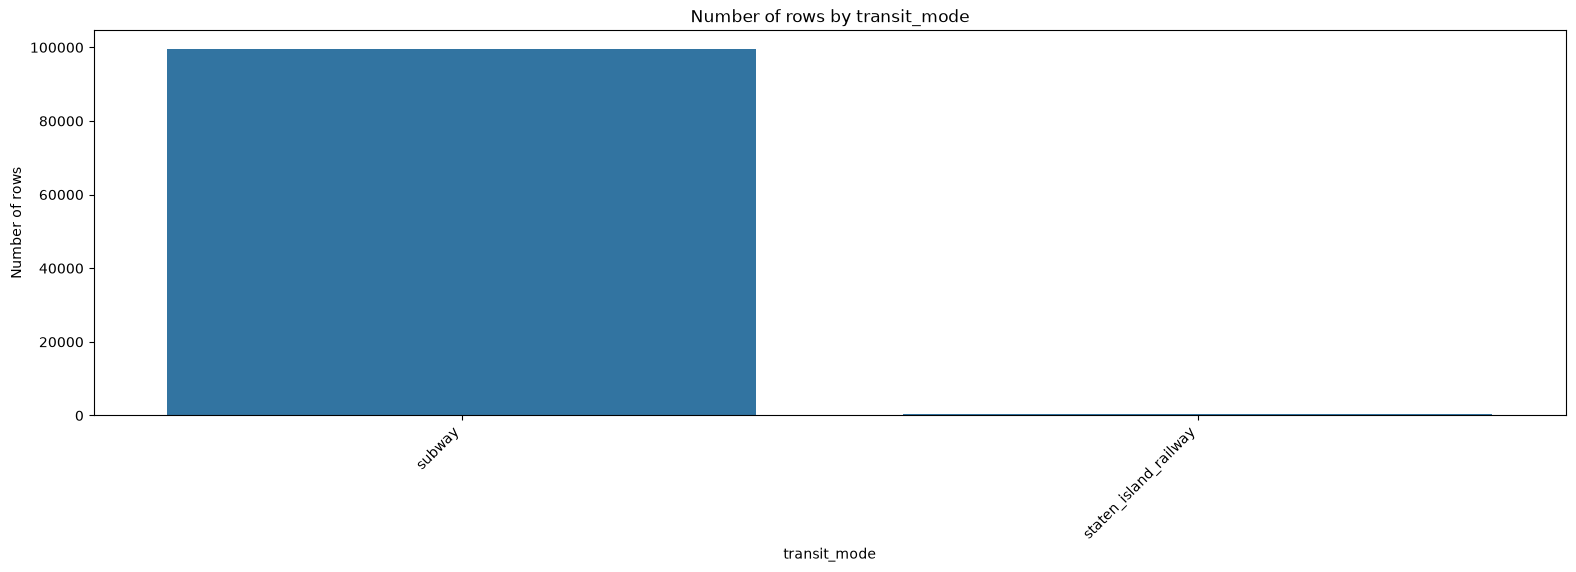

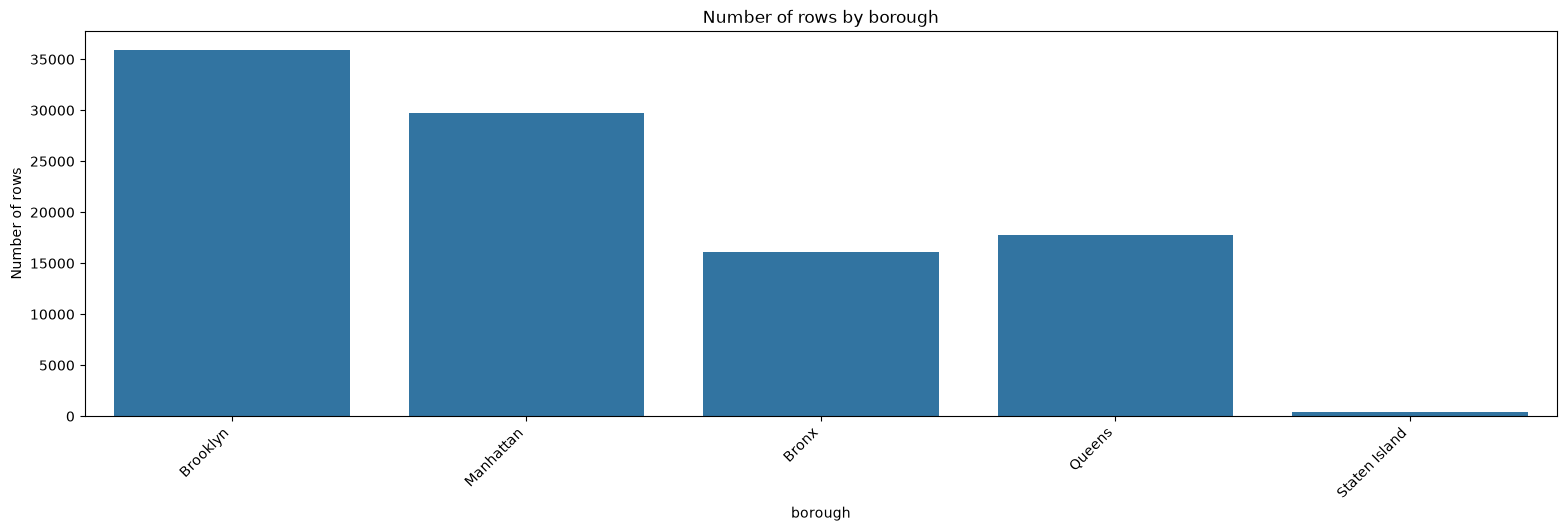

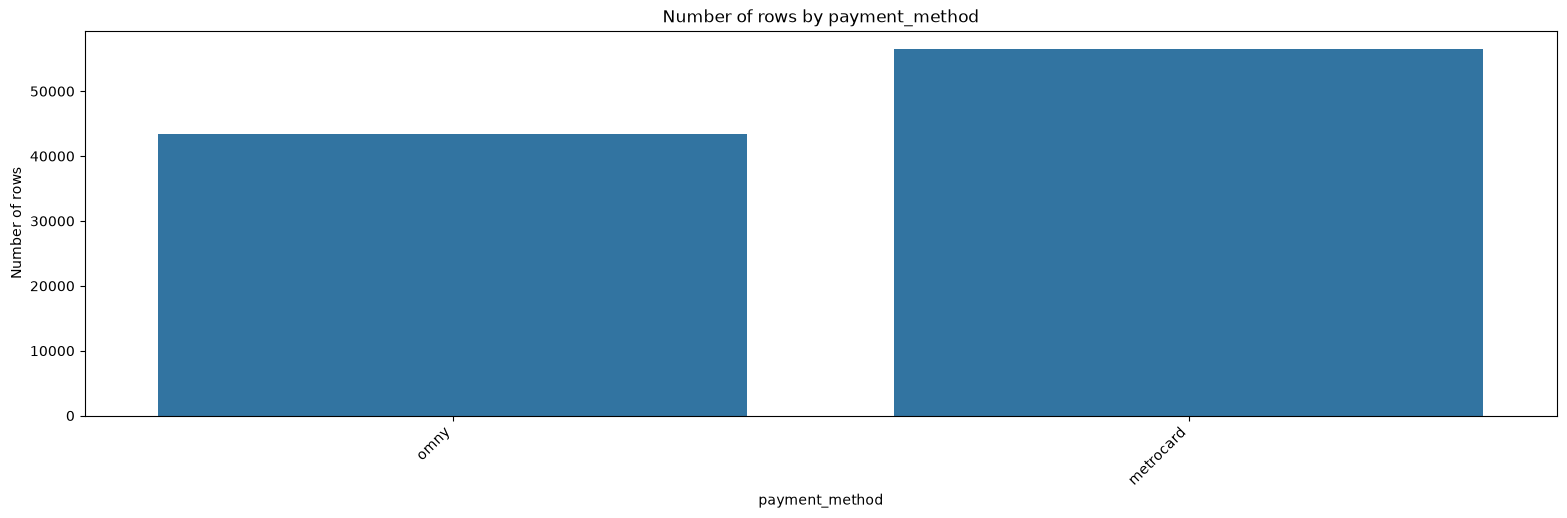

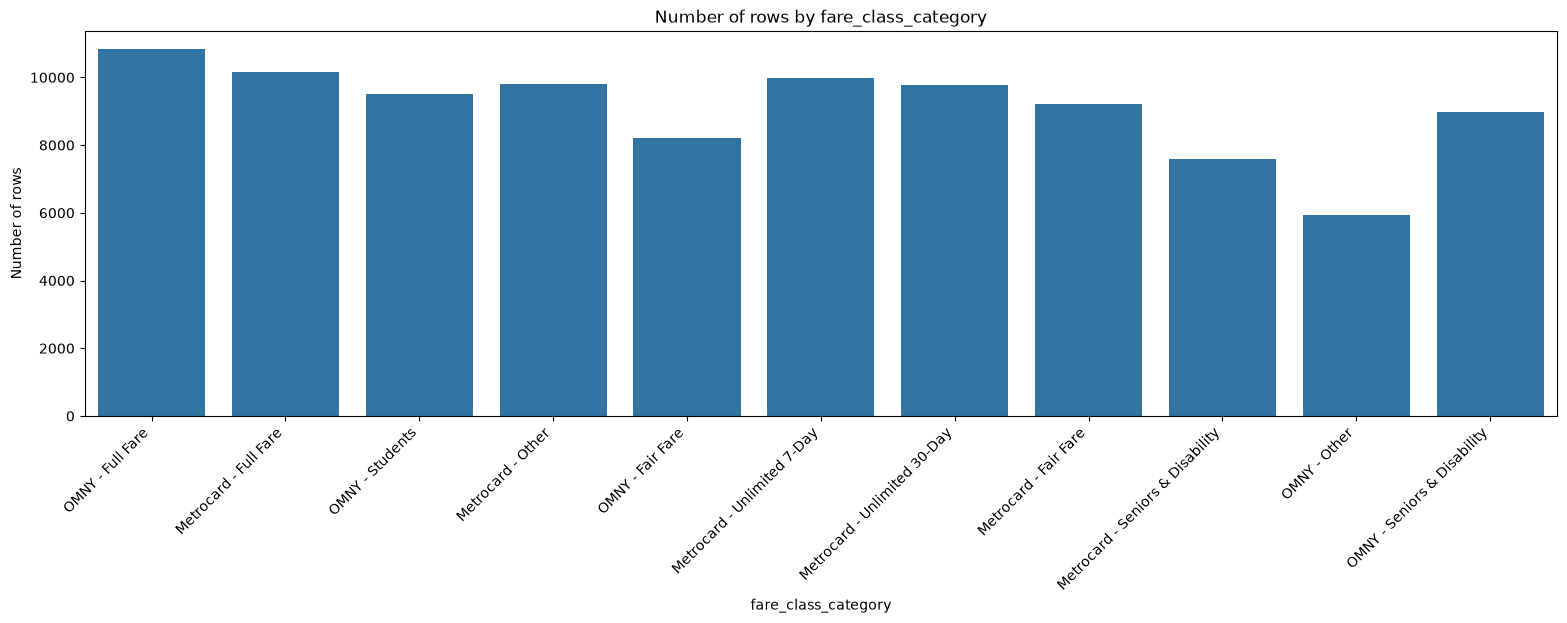

In [49]:
for column in numerical_columns:
    plt.figure(figsize=(19, 5))
    sns.countplot(x=column, data=df)
    plt.title(f'Number of rows by {column}')
    plt.xticks(rotation=45, ha='right')
    plt.ylabel('Number of rows')
    plt.xlabel(column)
    plt.show()